# ANN Lab 03 — Perceptron & Weight Initialization Techniques

Only NumPy is used for the perceptron itself. scikit-learn is used solely for loading data, splitting, scaling and metrics.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
SEED = 42

## Lab Task 1: Dataset Loading and Visualization

**Dataset:** Breast Cancer Wisconsin (Diagnostic) from the UCI Machine Learning Repository (bundled with scikit-learn, so no download is needed).
Task: classify a tumour as **malignant (0)** or **benign (1)** from 30 numeric features computed from cell-nucleus images.

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
print("Shape:", df.shape)
print("Number of features:", df.shape[1] - 1)
print("Target variable: 'target'  ->", dict(enumerate(data.target_names)))
print("\nFeature names:\n", list(data.feature_names))
print("\nMissing values per column (total):", int(df.isnull().sum().sum()))
df.head()

Shape: (569, 31)
Number of features: 30
Target variable: 'target'  -> {0: np.str_('malignant'), 1: np.str_('benign')}

Feature names:
 [np.str_('mean radius'), np.str_('mean texture'), np.str_('mean perimeter'), np.str_('mean area'), np.str_('mean smoothness'), np.str_('mean compactness'), np.str_('mean concavity'), np.str_('mean concave points'), np.str_('mean symmetry'), np.str_('mean fractal dimension'), np.str_('radius error'), np.str_('texture error'), np.str_('perimeter error'), np.str_('area error'), np.str_('smoothness error'), np.str_('compactness error'), np.str_('concavity error'), np.str_('concave points error'), np.str_('symmetry error'), np.str_('fractal dimension error'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst perimeter'), np.str_('worst area'), np.str_('worst smoothness'), np.str_('worst compactness'), np.str_('worst concavity'), np.str_('worst concave points'), np.str_('worst symmetry'), np.str_('worst fractal dimension')]

Missing values per

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
df.info()
df.describe().T.head(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


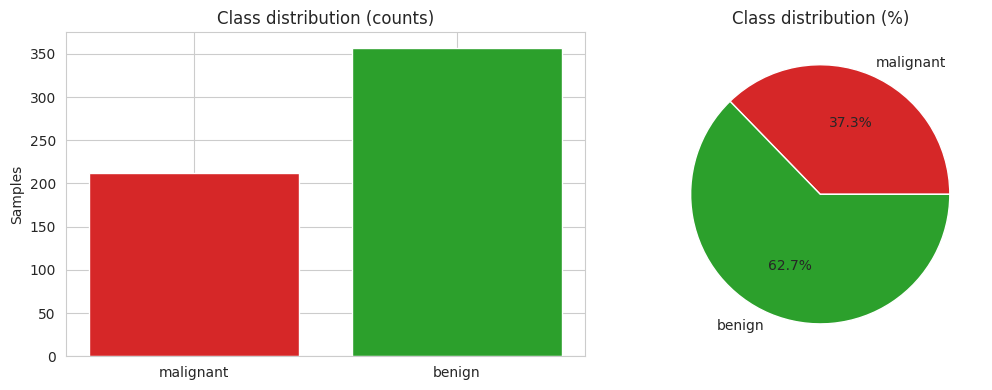

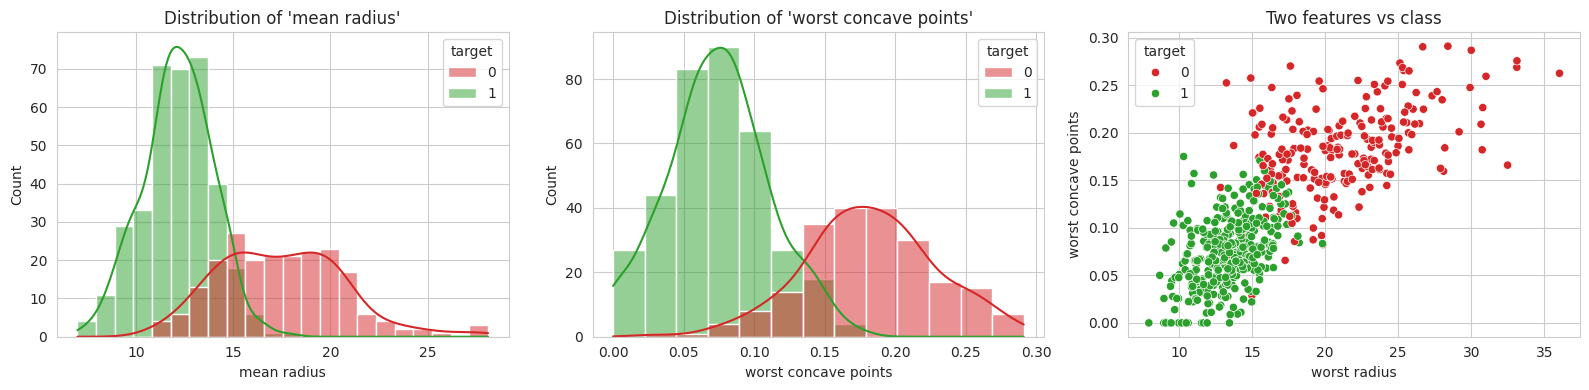

In [4]:
# Class distribution
counts = df["target"].value_counts().sort_index()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar([data.target_names[i] for i in counts.index], counts.values, color=["#d62728", "#2ca02c"])
ax[0].set_title("Class distribution (counts)"); ax[0].set_ylabel("Samples")
ax[1].pie(counts.values, labels=[data.target_names[i] for i in counts.index], autopct="%1.1f%%",
          colors=["#d62728", "#2ca02c"])
ax[1].set_title("Class distribution (%)")
plt.tight_layout(); plt.show()

# Feature distributions by class + scatter of two informative features
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for f, a in zip(["mean radius", "worst concave points"], ax[:2]):
    sns.histplot(data=df, x=f, hue="target", kde=True, palette=["#d62728", "#2ca02c"], ax=a)
    a.set_title(f"Distribution of '{f}'")
sns.scatterplot(data=df, x="worst radius", y="worst concave points", hue="target",
                palette=["#d62728", "#2ca02c"], ax=ax[2])
ax[2].set_title("Two features vs class")
plt.tight_layout(); plt.show()

In [5]:
# Train / test split (stratified) + standardisation (fit on train only -> no leakage)
X = df.drop(columns="target").values
y = df["target"].values

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y)

scaler = StandardScaler().fit(X_train_raw)
X_train = scaler.transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train class balance:", np.bincount(y_train), " Test class balance:", np.bincount(y_test))

Train: (426, 30)  Test: (143, 30)
Train class balance: [159 267]  Test class balance: [53 90]


## Lab Task 2: Basic Perceptron Implementation



In [6]:
# ---------- Weight initialisation schemes ----------
# A perceptron is a single neuron: weight matrix shape = (fan_out=1, fan_in=n_features)

def init_uniform(n_features, rng, low=-0.5, high=0.5):
    """'Default' random init: small uniform values."""
    return rng.uniform(low, high, size=n_features)

def init_gaussian(n_features, rng, mean=0.0, std=0.1):
    """Gaussian / Normal init  N(mean, std^2)."""
    return rng.normal(mean, std, size=n_features)

def init_xavier(n_features, rng, fan_out=1):
    """Xavier/Glorot normal: Var(w) = 2 / (fan_in + fan_out)."""
    std = np.sqrt(2.0 / (n_features + fan_out))
    return rng.normal(0.0, std, size=n_features)

def init_he(n_features, rng):
    """He/Kaiming normal: Var(w) = 2 / fan_in."""
    std = np.sqrt(2.0 / n_features)
    return rng.normal(0.0, std, size=n_features)

def init_orthogonal(n_features, rng, gain=1.0):
    """Orthogonal init: QR decomposition of a Gaussian matrix.
    For a (1 x n) weight matrix the rows are orthonormal, i.e. a random unit-norm vector (times gain)."""
    a = rng.normal(0.0, 1.0, size=(n_features, 1))       # (n x 1) so QR gives orthonormal columns
    q, r = np.linalg.qr(a)
    q = q * np.sign(np.diag(r))                           # make decomposition unique
    return gain * q.T.flatten()                            # shape (n_features,)

INITIALIZERS = {"Uniform (default)": init_uniform, "Gaussian": init_gaussian,
                "Xavier": init_xavier, "He": init_he, "Orthogonal": init_orthogonal}

In [7]:
class Perceptron:
    def __init__(self, lr=0.01, n_epochs=100, initializer=init_uniform, seed=SEED, shuffle_seed=SEED, pocket=False):
        self.lr, self.n_epochs, self.pocket = lr, n_epochs, pocket   # pocket=True keeps the best weights seen
        self.initializer, self.seed, self.shuffle_seed = initializer, seed, shuffle_seed

    def _init_params(self, n_features):
        rng = np.random.default_rng(self.seed)
        self.w = self.initializer(n_features, rng).astype(float)
        self.b = 0.0
        self.w_init, self.b_init = self.w.copy(), self.b

    def net_input(self, X):
        return X @ self.w + self.b

    def predict(self, X):
        return np.where(self.net_input(X) >= 0.0, 1, 0)

    def fit(self, X, y):
        self._init_params(X.shape[1])
        shuffler = np.random.default_rng(self.shuffle_seed)   # identical sample order for every run
        self.errors_ = []            # misclassifications during each epoch (training error count)
        self.train_err_rate_ = []    # error rate on the full train set measured at end of each epoch
        self.converged_epoch_ = None # first epoch with 0 training errors (None if never)
        for epoch in range(1, self.n_epochs + 1):
            errors = 0
            for i in shuffler.permutation(len(X)):
                update = self.lr * (y[i] - self.predict(X[i:i+1])[0])
                self.w += update * X[i]
                self.b += update
                errors += int(update != 0.0)
            self.errors_.append(errors)
            self.train_err_rate_.append(np.mean(self.predict(X) != y))
            if self.pocket and self.train_err_rate_[-1] <= min(self.train_err_rate_):
                self._pw, self._pb = self.w.copy(), self.b
            if errors == 0 and self.converged_epoch_ is None:
                self.converged_epoch_ = epoch
                break                                          # perfectly separated -> stop
        # "epochs to converge": zero-error epoch if reached, otherwise epoch where best (lowest) error was first hit
        best = int(np.argmin(self.train_err_rate_)) + 1
        self.best_epoch_ = best
        self.n_epochs_run_ = len(self.errors_)
        if self.pocket:
            self.w, self.b = self._pw, self._pb
        return self

    def score(self, X, y):
        return np.mean(self.predict(X) == y)

### Task 2.3–2.4: Train (default init) and evaluate on the test set

In [8]:
LR, EPOCHS = 0.01, 100
p0 = Perceptron(lr=LR, n_epochs=EPOCHS, initializer=init_uniform).fit(X_train, y_train)
print(f"Epochs run            : {p0.n_epochs_run_}")
print(f"Train accuracy        : {p0.score(X_train, y_train):.4f}")
print(f"Test accuracy         : {p0.score(X_test, y_test):.4f}")

Epochs run            : 100
Train accuracy        : 0.9906
Test accuracy         : 0.9510


## Lab Task 3: Learning Curve and Weight Visualization

The training error (number of misclassified samples in each epoch, plus the end-of-epoch error rate) is recorded inside `fit()`.

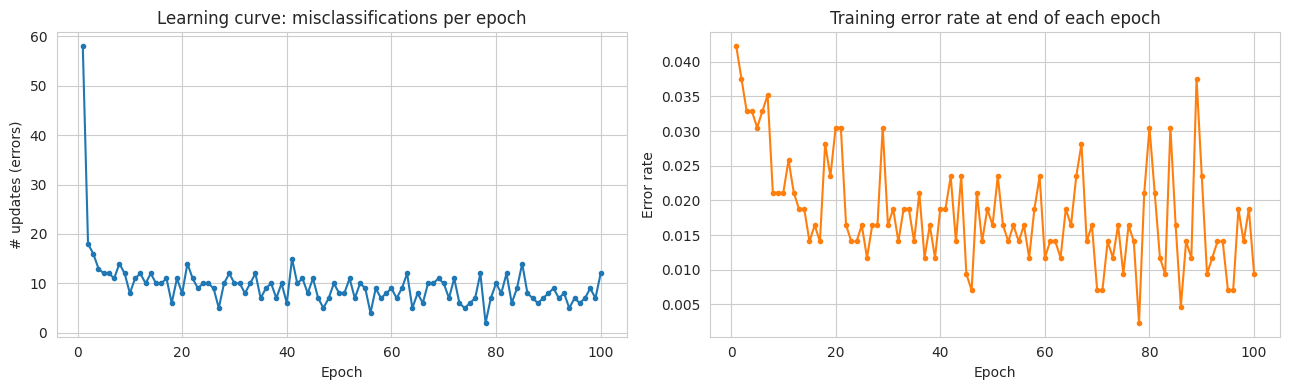

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(range(1, len(p0.errors_)+1), p0.errors_, marker="o", ms=3)
ax[0].set_title("Learning curve: misclassifications per epoch")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("# updates (errors)")
ax[1].plot(range(1, len(p0.train_err_rate_)+1), p0.train_err_rate_, marker="o", ms=3, color="tab:orange")
ax[1].set_title("Training error rate at end of each epoch")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Error rate")
plt.tight_layout(); plt.show()

Final bias: -0.03

Final weights (sorted):


,weight
worst concavity,-0.3941
radius error,-0.3515
mean concavity,-0.3307
mean fractal dimension,-0.3171
worst concave points,-0.3045
worst texture,-0.2882
worst symmetry,-0.2330
mean area,-0.2107
compactness error,-0.1996
area error,-0.1928


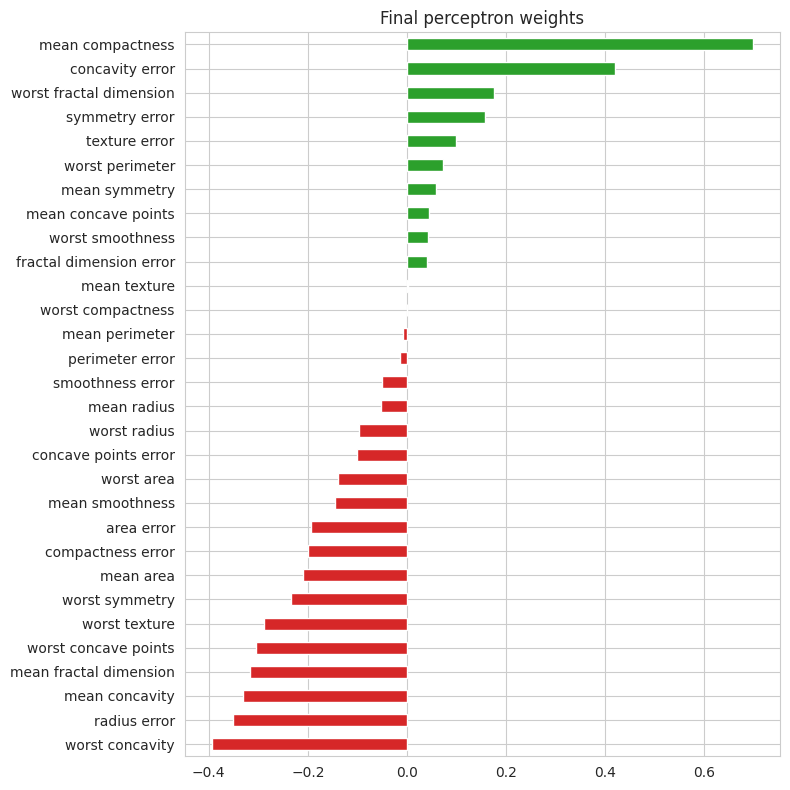

In [10]:
print("Final bias:", round(p0.b, 4))
w_df = pd.Series(p0.w, index=data.feature_names, name="weight").sort_values()
print("\nFinal weights (sorted):"); display(w_df.round(4).to_frame())
plt.figure(figsize=(8, 8)); w_df.plot.barh(color=np.where(w_df < 0, "tab:red", "tab:green"))
plt.title("Final perceptron weights"); plt.tight_layout(); plt.show()

### Decision boundary
With 30 features the boundary is a hyperplane in 30-D space and cannot be drawn directly. To visualise it, I train a perceptron on **two** features (`worst radius`, `worst concave points`) and plot the line $w_1x_1 + w_2x_2 + b = 0$.

2-feature perceptron  -> test accuracy: 0.9371
w = [-0.0237 -0.0205]  b = 0.01


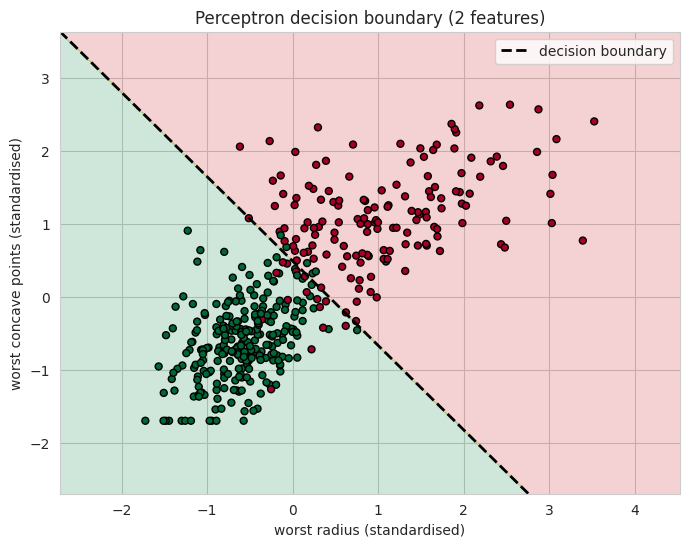

In [11]:
f1, f2 = list(data.feature_names).index("worst radius"), list(data.feature_names).index("worst concave points")
X2_tr, X2_te = X_train[:, [f1, f2]], X_test[:, [f1, f2]]
# pocket=True keeps the best weights seen (the data is not separable in 2-D, so the last iterate is noisy)
p2d = Perceptron(lr=LR, n_epochs=EPOCHS, initializer=init_gaussian, pocket=True).fit(X2_tr, y_train)
print(f"2-feature perceptron  -> test accuracy: {p2d.score(X2_te, y_test):.4f}")
print("w =", p2d.w.round(4), " b =", round(p2d.b, 4))

xx, yy = np.meshgrid(np.linspace(X2_tr[:,0].min()-1, X2_tr[:,0].max()+1, 300),
                     np.linspace(X2_tr[:,1].min()-1, X2_tr[:,1].max()+1, 300))
zz = p2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, zz, alpha=0.2, cmap="RdYlGn")
plt.scatter(X2_tr[:,0], X2_tr[:,1], c=y_train, cmap="RdYlGn", edgecolor="k", s=25)
xs = np.array([xx.min(), xx.max()])
plt.plot(xs, -(p2d.w[0]*xs + p2d.b)/p2d.w[1], "k--", lw=2, label="decision boundary")
plt.ylim(yy.min(), yy.max()); plt.xlabel("worst radius (standardised)"); plt.ylabel("worst concave points (standardised)")
plt.legend(); plt.title("Perceptron decision boundary (2 features)"); plt.show()

**Explanation.** The perceptron predicts class 1 (benign) when $w\cdot x + b \ge 0$ and class 0 (malignant) otherwise. The dashed line is exactly where $w\cdot x+b=0$; it is a straight line in 2-D (a hyperplane in 30-D). The weight vector $w$ is *perpendicular* to the boundary and points toward the benign side, while the bias shifts the line away from the origin. Negative weights on size-related features (radius, concave points) mean larger/more irregular nuclei push the score toward "malignant", which matches the medical intuition. Points on the wrong side of the line are the ones that trigger weight updates during training.

## Lab Tasks 4–7: Initialization experiments

All experiments below use the **same dataset, learning rate (0.01), max epochs (100), shuffling order and seed**; only the initial weights change. A helper runs one configuration and stores the results so that later tasks can compare them. Bias starts at 0 in all cases.

| Method | Distribution | Std / scale for our perceptron (fan_in = 30, fan_out = 1) |
|---|---|---|
| Gaussian | $N(0, 0.1^2)$ | 0.1 |
| Xavier/Glorot (normal) | $N(0, \frac{2}{fan_{in}+fan_{out}})$ | $\sqrt{2/31}\approx 0.254$ |
| He/Kaiming (normal) | $N(0, \frac{2}{fan_{in}})$ | $\sqrt{2/30}\approx 0.258$ |
| Orthogonal | QR of Gaussian matrix | unit-norm weight vector (‖w‖ = 1) |

*Convergence epoch* = first epoch with zero training errors. If the data is not perfectly separable within the epoch budget, the perceptron cannot reach that state, so I also report the epoch at which the lowest training error was first reached ("best epoch").

In [12]:
results = {}

def run_experiment(name, initializer, X_tr=X_train, y_tr=y_train, X_te=X_test, y_te=y_test,
                   lr=LR, epochs=EPOCHS, seed=SEED):
    m = Perceptron(lr=lr, n_epochs=epochs, initializer=initializer, seed=seed).fit(X_tr, y_tr)
    res = dict(model=m, converged=m.converged_epoch_ is not None,
               conv_epoch=m.converged_epoch_, best_epoch=m.best_epoch_,
               final_train_err=m.train_err_rate_[-1], min_train_err=min(m.train_err_rate_),
               train_acc=m.score(X_tr, y_tr), test_acc=m.score(X_te, y_te))
    results[name] = res
    return res

def report(name):
    r, m = results[name], results[name]["model"]
    print(f"[{name}]")
    print(f"  Converged (0 train errors): {r['converged']}   epoch: {r['conv_epoch']}   best epoch: {r['best_epoch']}")
    print(f"  Final train error rate: {r['final_train_err']:.4f}   Train acc: {r['train_acc']:.4f}   Test acc: {r['test_acc']:.4f}")
    print(f"  ||w_init|| = {np.linalg.norm(m.w_init):.4f}   ||w_final|| = {np.linalg.norm(m.w):.4f}   bias = {m.b:.4f}")

def plot_curve(name, color="tab:blue"):
    m = results[name]["model"]
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(range(1, len(m.errors_)+1), m.errors_, marker="o", ms=3, color=color)
    ax.set_title(f"Learning curve — {name} initialization"); ax.set_xlabel("Epoch"); ax.set_ylabel("Errors per epoch")
    plt.show()

run_experiment("Uniform (default)", init_uniform)

{'model': <__main__.Perceptron at 0x7b7970616490>,
 'converged': False,
 'conv_epoch': None,
 'best_epoch': 78,
 'final_train_err': np.float64(0.009389671361502348),
 'min_train_err': np.float64(0.002347417840375587),
 'train_acc': np.float64(0.9906103286384976),
 'test_acc': np.float64(0.951048951048951)}

### Task 4: Gaussian initialization

[Uniform (default)]
  Converged (0 train errors): False   epoch: None   best epoch: 78
  Final train error rate: 0.0094   Train acc: 0.9906   Test acc: 0.9510
  ||w_init|| = 1.6261   ||w_final|| = 1.2838   bias = -0.0300
[Gaussian]
  Converged (0 train errors): False   epoch: None   best epoch: 91
  Final train error rate: 0.0117   Train acc: 0.9883   Test acc: 0.9650
  ||w_init|| = 0.4184   ||w_final|| = 0.7899   bias = -0.0500


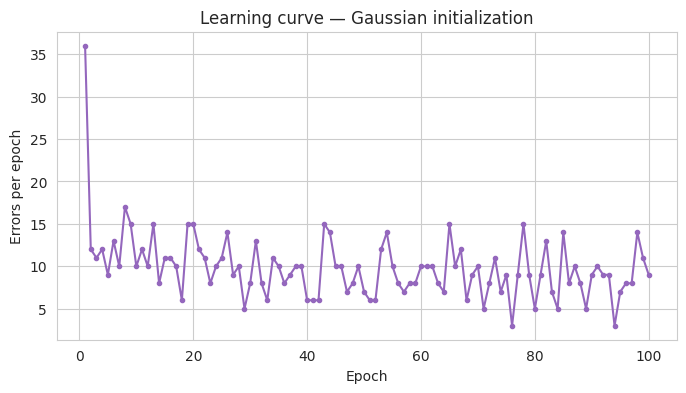

In [13]:
run_experiment("Gaussian", lambda n, rng: init_gaussian(n, rng, mean=0.0, std=0.1))
report("Uniform (default)"); report("Gaussian"); plot_curve("Gaussian", "tab:purple")

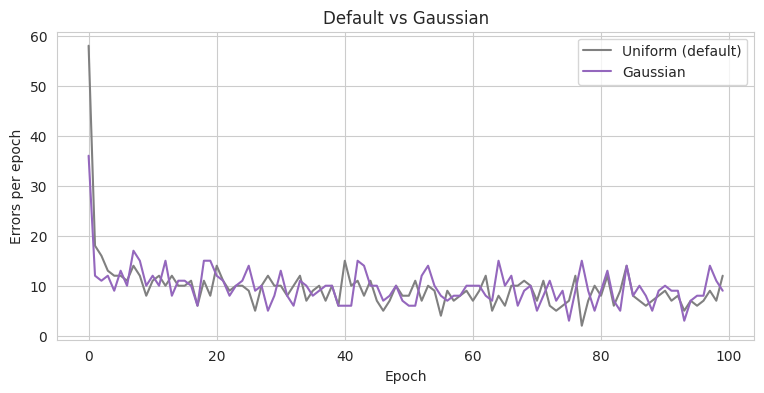

Correlation of final weights (default vs Gaussian): 0.8943


,Uniform (default),Gaussian
mean radius,-0.052,0.000
mean texture,0.002,-0.016
mean perimeter,-0.008,0.049
mean area,-0.211,0.002
mean smoothness,-0.146,-0.086
mean compactness,0.698,0.363
mean concavity,-0.331,-0.157
mean concave points,0.045,-0.043
mean symmetry,0.058,0.033
mean fractal dimension,-0.317,-0.139


In [14]:
# Comparison: default vs Gaussian
fig, ax = plt.subplots(figsize=(9, 4))
for n, c in [("Uniform (default)", "gray"), ("Gaussian", "tab:purple")]:
    ax.plot(results[n]["model"].errors_, label=n, color=c)
ax.set_xlabel("Epoch"); ax.set_ylabel("Errors per epoch"); ax.legend(); ax.set_title("Default vs Gaussian"); plt.show()

cmp = pd.DataFrame({n: results[n]["model"].w for n in ["Uniform (default)", "Gaussian"]}, index=data.feature_names)
print("Correlation of final weights (default vs Gaussian):", round(cmp.corr().iloc[0,1], 4))
cmp.round(3).head(10)

**Comparison (Task 4).** Neither run reaches zero training errors within 100 epochs (the breast-cancer data is *almost* but not perfectly separable for a perceptron), so "convergence" is judged by when the lowest training error is reached and how low it gets. Both runs end around 1 % training error and 95–96 % test accuracy. The final weight vectors are strongly correlated (≈0.9): the data-driven updates dominate the small starting weights, so both end up in a similar region of weight space. Note that the default uniform start had a *larger* initial norm (‖w‖≈1.6) than Gaussian (≈0.4), and it ended with a larger final norm as well — a smaller start leaves less to "unlearn".

### Task 5: Xavier/Glorot initialization

[Xavier]
  Converged (0 train errors): False   epoch: None   best epoch: 51
  Final train error rate: 0.0188   Train acc: 0.9812   Test acc: 0.9371
  ||w_init|| = 1.0627   ||w_final|| = 0.8451   bias = -0.0700


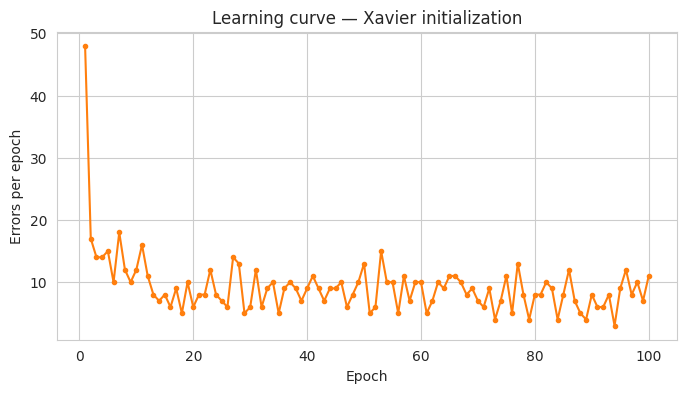

Gaussian epochs (conv/best): None 91 | Xavier epochs (conv/best): None 51


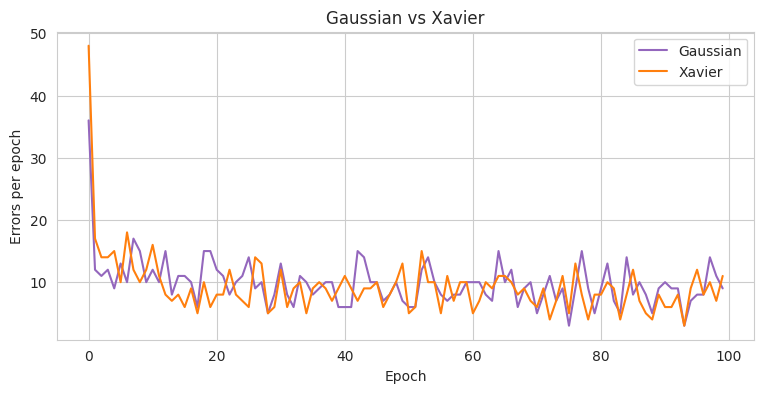

In [15]:
run_experiment("Xavier", init_xavier)
report("Xavier"); plot_curve("Xavier", "tab:orange")
print("Gaussian epochs (conv/best):", results["Gaussian"]["conv_epoch"], results["Gaussian"]["best_epoch"],
      "| Xavier epochs (conv/best):", results["Xavier"]["conv_epoch"], results["Xavier"]["best_epoch"])
fig, ax = plt.subplots(figsize=(9, 4))
for n, c in [("Gaussian", "tab:purple"), ("Xavier", "tab:orange")]:
    ax.plot(results[n]["model"].errors_, label=n, color=c)
ax.set_xlabel("Epoch"); ax.set_ylabel("Errors per epoch"); ax.legend(); ax.set_title("Gaussian vs Xavier"); plt.show()

**Discussion (Task 5).** (In our run Xavier reached its lowest training error earlier (epoch 51 vs 91) but finished with a slightly higher final training error and a lower test accuracy than Gaussian. With a 143-sample test set, one sample is ≈0.7 %, so such differences are within noise.) Xavier scales the variance by the layer size ($2/(fan_{in}+fan_{out})$), so the initial weights are larger than my fixed Gaussian (std 0.1) and the initial pre-activation $w\cdot x$ has a variance that is independent of the number of features. It was designed to keep signal variance stable across *deep* layers with tanh/sigmoid activations. For a single perceptron with a hard threshold there is no depth to propagate through, so any effect is limited to the size of the starting point relative to the updates (lr = 0.01).

### Task 6: He/Kaiming initialization

[He]
  Converged (0 train errors): False   epoch: None   best epoch: 95
  Final train error rate: 0.0164   Train acc: 0.9836   Test acc: 0.9441
  ||w_init|| = 1.0803   ||w_final|| = 0.8448   bias = -0.0600


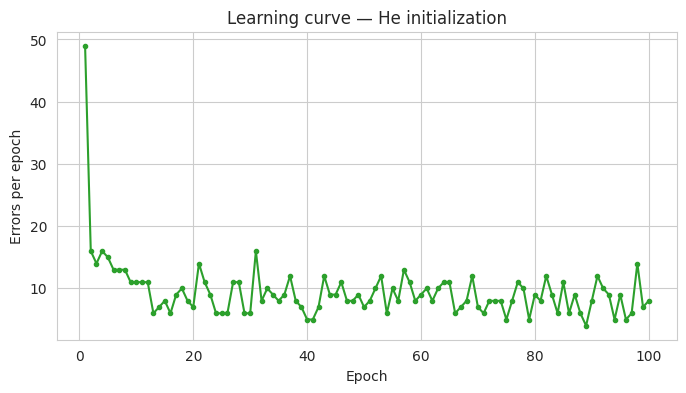

,Convergence epoch,Best epoch,Test accuracy
Gaussian,NaN,91.0,0.965035
Xavier,NaN,51.0,0.937063
He,NaN,95.0,0.944056


In [16]:
run_experiment("He", init_he)
report("He"); plot_curve("He", "tab:green")
pd.DataFrame({k: [results[k]["conv_epoch"], results[k]["best_epoch"], results[k]["test_acc"]] for k in ["Gaussian", "Xavier", "He"]},
             index=["Convergence epoch", "Best epoch", "Test accuracy"]).T

**Comparison (Task 6).** He uses $2/fan_{in}$, which is designed for ReLU layers (half of the units are inactive, so the variance is doubled). Here fan_out = 1, so $2/30 \approx 2/31$ and He is almost identical to Xavier; differences between them are tiny and mainly come from the slightly different standard deviation (0.258 vs 0.254). Both are ≈2.5× larger than the chosen Gaussian std of 0.1. In our run their final weight vectors are almost identical (correlation ≈0.99) and their final training errors are close, which supports this.

### Task 7: Orthogonal initialization

[Orthogonal]
  Converged (0 train errors): False   epoch: None   best epoch: 95
  Final train error rate: 0.0164   Train acc: 0.9836   Test acc: 0.9720
  ||w_init|| = 1.0000   ||w_final|| = 0.8451   bias = -0.0500


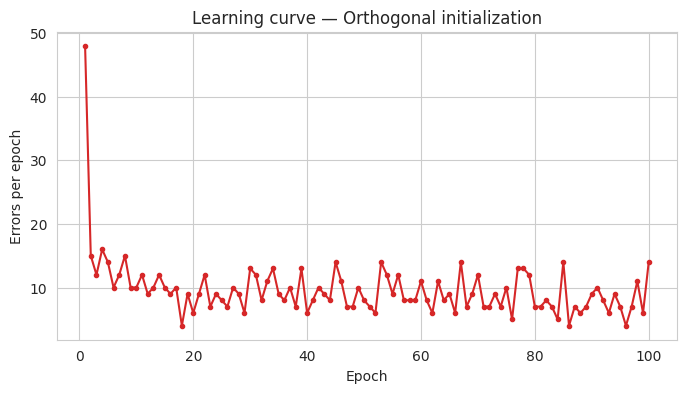

Row norm of orthogonal init (should be 1): 1.0


In [17]:
run_experiment("Orthogonal", init_orthogonal)
report("Orthogonal"); plot_curve("Orthogonal", "tab:red")
print("Row norm of orthogonal init (should be 1):", np.linalg.norm(results["Orthogonal"]["model"].w_init).round(6))

**Comparison (Task 7).** For a single neuron the weight "matrix" has one row, so orthogonality reduces to a unit-norm random vector (‖w‖=1). Its initial norm (1.0) is about 2.4× that of the Gaussian start (≈0.42) and about the same as Xavier/He (≈1.06–1.08), so it mainly differs from those two by having a *fixed* norm rather than a random one. Its final weights are nearly identical to Xavier/He (correlation ≈0.99). The orthogonality benefit (decorrelated neurons, preserved norm through layers) only materialises in multi-neuron, multi-layer networks.

## Lab Task 8: Comparative Analysis

In [18]:
methods = ["Gaussian", "Xavier", "He", "Orthogonal"]
summary = pd.DataFrame({
    m: {"Converged (0 err)": results[m]["converged"],
        "Convergence epoch": results[m]["conv_epoch"],
        "Best epoch": results[m]["best_epoch"],
        "Epochs run": results[m]["model"].n_epochs_run_,
        "Final train error": round(results[m]["final_train_err"], 4),
        "Test accuracy": round(results[m]["test_acc"], 4),
        "||w_init||": round(np.linalg.norm(results[m]["model"].w_init), 3),
        "||w_final||": round(np.linalg.norm(results[m]["model"].w), 3),
        "Final bias": round(results[m]["model"].b, 4)} for m in methods}).T
display(summary)

weights_df = pd.DataFrame({m: results[m]["model"].w for m in methods}, index=data.feature_names)
print("Final weight values for each method:"); display(weights_df.round(4))
print("Correlation between final weight vectors:"); display(weights_df.corr().round(3))

,Converged (0 err),Convergence epoch,Best epoch,Epochs run,Final train error,Test accuracy,||w_init||,||w_final||,Final bias
Gaussian,False,None,91,100,0.0117,0.965,0.418,0.79,-0.05
Xavier,False,None,51,100,0.0188,0.9371,1.063,0.845,-0.07
He,False,None,95,100,0.0164,0.9441,1.08,0.845,-0.06
Orthogonal,False,None,95,100,0.0164,0.972,1.0,0.845,-0.05


Final weight values for each method:


,Gaussian,Xavier,He,Orthogonal
mean radius,0.0004,-0.0439,-0.0654,-0.0440
mean texture,-0.0159,-0.0142,0.0026,-0.0116
mean perimeter,0.0494,0.0827,0.0743,0.0877
mean area,0.0021,0.0282,0.0362,0.0362
mean smoothness,-0.0856,-0.0683,-0.0869,-0.0875
mean compactness,0.3626,0.3520,0.3618,0.3673
mean concavity,-0.1574,-0.1782,-0.1423,-0.1856
mean concave points,-0.0425,-0.0386,-0.0664,-0.0389
mean symmetry,0.0329,0.0172,0.0129,0.0155
mean fractal dimension,-0.1386,-0.1641,-0.1322,-0.1534


Correlation between final weight vectors:


,Gaussian,Xavier,He,Orthogonal
Gaussian,1.000,0.962,0.960,0.966
Xavier,0.962,1.000,0.992,0.994
He,0.960,0.992,1.000,0.989
Orthogonal,0.966,0.994,0.989,1.000


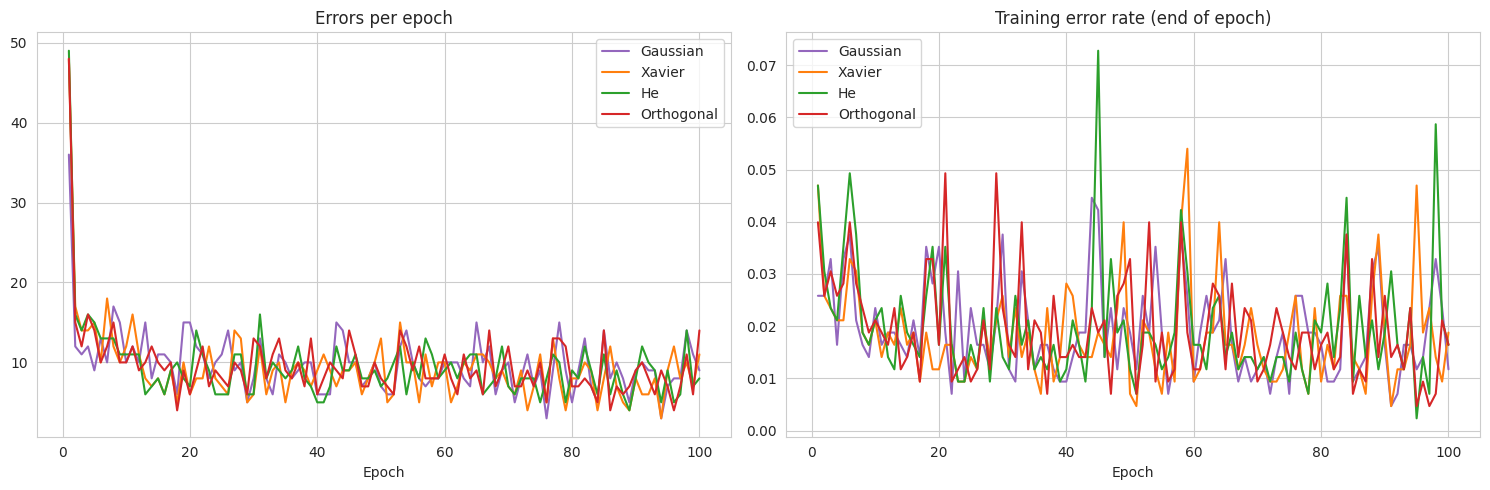

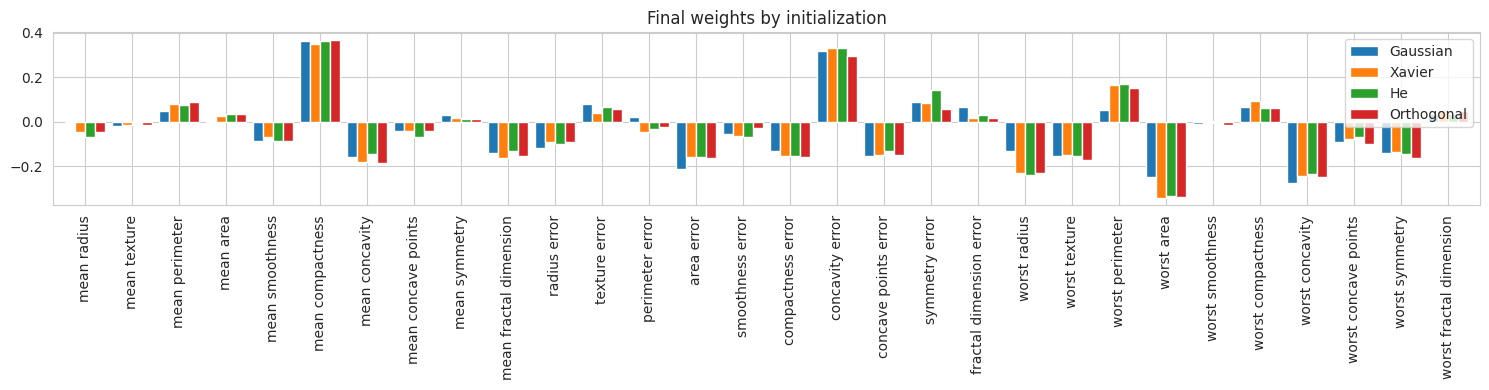

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
colors = dict(zip(methods, ["tab:purple", "tab:orange", "tab:green", "tab:red"]))
for m in methods:
    e = results[m]["model"].errors_
    ax[0].plot(range(1, len(e)+1), e, label=m, color=colors[m])
    r = results[m]["model"].train_err_rate_
    ax[1].plot(range(1, len(r)+1), r, label=m, color=colors[m])
ax[0].set_title("Errors per epoch"); ax[1].set_title("Training error rate (end of epoch)")
for a in ax: a.set_xlabel("Epoch"); a.legend()
plt.tight_layout(); plt.show()

weights_df.plot.bar(figsize=(15, 4), width=0.85); plt.title("Final weights by initialization"); plt.tight_layout(); plt.show()

### Analysis (Task 8)

*Why can different initializations give different training behaviour?*

1. **Starting point.** The perceptron learning rule is a mistake-driven update. Where you start in weight space decides which samples are misclassified initially and therefore the order and size of the first updates. A start that is already well aligned with the separating hyperplane needs fewer corrections.
2. **Scale of the initial weights.** Weights with large norm (Xavier, He, Orthogonal here) produce large initial scores $w\cdot x$. With a small learning rate (0.01) the updates need many steps to overturn a large wrong initial weight, whereas a small-norm start (the Gaussian with std 0.1) is quickly dominated by the data-driven updates. Since the perceptron output is a hard threshold, only the *direction* of $w$ matters for prediction, but the norm changes how fast the direction can be corrected.
3. **Randomness vs. design.** Xavier and He are derived for *deep* networks to keep activation/gradient variance stable across layers; with one neuron and fan_out = 1 they collapse to nearly the same Gaussian with different std. Orthogonal initialization adds a fixed norm, which removes the variance in ‖w‖ that the Gaussian schemes have.
4. **Non-separable data.** When data is not perfectly linearly separable the perceptron never reaches zero errors and keeps oscillating; the epoch at which it stops improving and the final error then depend strongly on the sample order and the last few updates, so differences between initializations can be noise rather than a systematic effect. Task 9 quantifies this by averaging over seeds.

**What this run shows.** None of the four initializations reached zero training errors in 100 epochs. Final training error rates were all ≈1–2 %, and test accuracies ranged from ≈93.7 % to ≈97.2 % (a difference of only a few samples out of 143). Xavier, He and Orthogonal — which all start with ‖w‖≈1 — ended with nearly identical final weights (pairwise correlation ≈0.99) and the same final norm (≈0.845), while Gaussian, which started with a smaller norm, ended with a slightly different weight vector (correlation ≈0.96). So initial scale left a visible fingerprint on the final weights, but no clear winner in accuracy. A single run is weak evidence, which is why Task 9 repeats the experiment with multiple seeds.

## Lab Task 9: Experimental Study and Interpretation

**Second dataset:** Pima Indians Diabetes (UCI / Kaggle) via OpenML — 8 medical features, binary target (diabetes yes/no). It is a *noisy, not linearly separable* dataset, in contrast to the nearly separable breast-cancer data, so it stresses the perceptron differently. If OpenML can't be reached (no internet), the code falls back to a synthetic overlapping-class dataset.

Each initialization is run with **10 random seeds** (seed changes the initial weights, the sample-shuffling order *and* the train/test split so the results reflect real run-to-run variability).

Pima Indians Diabetes (768, 8) class counts: [500 268]
Missing values: 0


,preg,plas,pres,skin,insu,mass,pedi,age,target
0,6.0,148.0,72.0,35.0,0.0,33.6,0.627,50.0,1
1,1.0,85.0,66.0,29.0,0.0,26.6,0.351,31.0,0
2,8.0,183.0,64.0,0.0,0.0,23.3,0.672,32.0,1
3,1.0,89.0,66.0,23.0,94.0,28.1,0.167,21.0,0
4,0.0,137.0,40.0,35.0,168.0,43.1,2.288,33.0,1


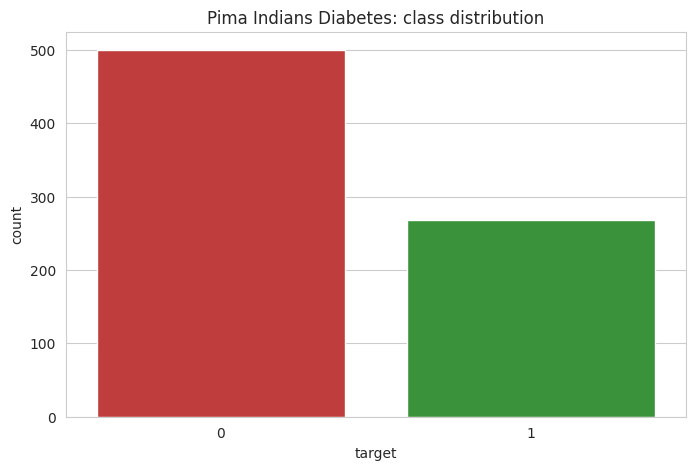

In [20]:
from sklearn.datasets import fetch_openml, make_classification
try:
    d2 = fetch_openml("diabetes", version=1, as_frame=True, parser="auto")
    X2_all = d2.data.values.astype(float)
    y2_all = (d2.target == "tested_positive").astype(int).values
    ds2_name = "Pima Indians Diabetes"
    feat2 = list(d2.data.columns)
except Exception as e:
    print("OpenML unavailable -> using synthetic fallback dataset:", type(e).__name__)
    X2_all, y2_all = make_classification(n_samples=768, n_features=8, n_informative=5, n_redundant=1,
                                         flip_y=0.05, class_sep=1.0, random_state=SEED)
    ds2_name = "Synthetic (make_classification)"; feat2 = [f"f{i}" for i in range(8)]

print(ds2_name, X2_all.shape, "class counts:", np.bincount(y2_all))
df2 = pd.DataFrame(X2_all, columns=feat2); df2["target"] = y2_all
print("Missing values:", int(df2.isnull().sum().sum()))
display(df2.head())
sns.countplot(x="target", hue="target", data=df2, palette=["#d62728", "#2ca02c"], legend=False); plt.title(f"{ds2_name}: class distribution"); plt.show()

In [21]:
SEEDS = list(range(10))
INITS9 = {"Gaussian": lambda n, rng: init_gaussian(n, rng, 0.0, 0.1),
          "Xavier": init_xavier, "He": init_he, "Orthogonal": init_orthogonal}
rows = []
for seed in SEEDS:
    Xa, Xb, ya, yb = train_test_split(X2_all, y2_all, test_size=0.25, random_state=seed, stratify=y2_all)
    sc = StandardScaler().fit(Xa); Xa, Xb = sc.transform(Xa), sc.transform(Xb)
    for name, init in INITS9.items():
        m = Perceptron(lr=LR, n_epochs=EPOCHS, initializer=init, seed=seed, shuffle_seed=seed).fit(Xa, ya)
        rows.append(dict(seed=seed, init=name, converged=m.converged_epoch_ is not None,
                         conv_epoch=m.converged_epoch_ if m.converged_epoch_ else np.nan,
                         best_epoch=m.best_epoch_, final_train_err=m.train_err_rate_[-1],
                         min_train_err=min(m.train_err_rate_), test_acc=m.score(Xb, yb)))
runs = pd.DataFrame(rows)
display(runs.pivot(index="seed", columns="init", values="test_acc").round(4))

init,Gaussian,He,Orthogonal,Xavier
seed,,,,
0,0.6927,0.6302,0.7448,0.6302
1,0.7188,0.6979,0.7344,0.7188
2,0.6823,0.6927,0.6771,0.6510
3,0.7344,0.7292,0.7448,0.7240
4,0.6771,0.6823,0.6927,0.7135
5,0.6719,0.6615,0.6719,0.5885
6,0.7708,0.7656,0.7865,0.7917
7,0.6719,0.7083,0.6302,0.6510
8,0.5833,0.6146,0.6198,0.5938


,runs_converged,avg_conv_epoch,avg_best_epoch,std_best_epoch,avg_final_train_err,avg_min_train_err,avg_test_acc,std_test_acc
init,,,,,,,,
Gaussian,0,NaN,30.4,32.6095,0.2922,0.2255,0.6943,0.0515
Xavier,0,NaN,43.4,33.2439,0.2990,0.2222,0.6781,0.0654
He,0,NaN,23.0,23.3476,0.2884,0.2260,0.6927,0.0480
Orthogonal,0,NaN,41.1,22.2284,0.2870,0.2233,0.7016,0.0532


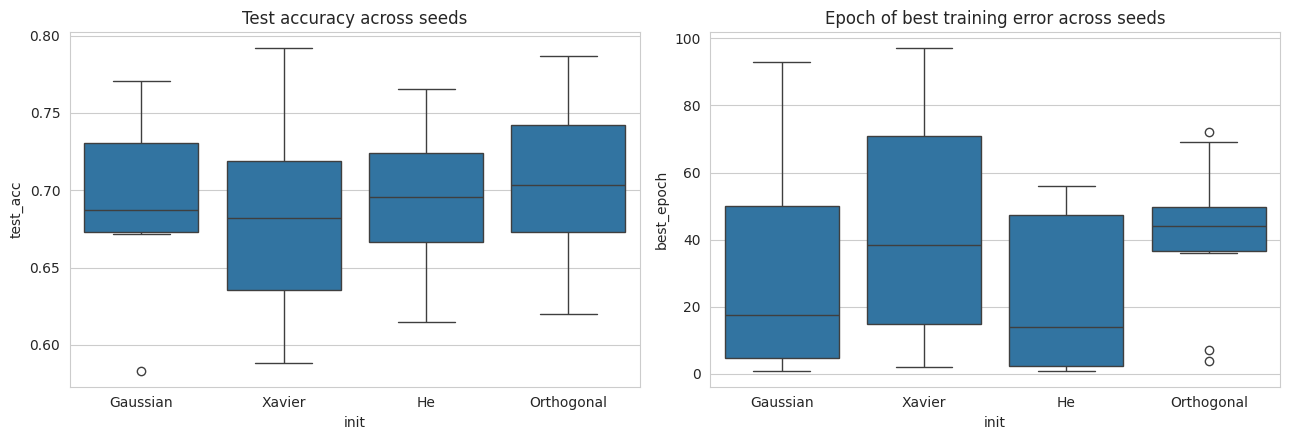

In [22]:
agg = runs.groupby("init").agg(
    runs_converged=("converged", "sum"),
    avg_conv_epoch=("conv_epoch", "mean"),
    avg_best_epoch=("best_epoch", "mean"),
    std_best_epoch=("best_epoch", "std"),
    avg_final_train_err=("final_train_err", "mean"),
    avg_min_train_err=("min_train_err", "mean"),
    avg_test_acc=("test_acc", "mean"),
    std_test_acc=("test_acc", "std")).loc[list(INITS9)]
display(agg.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=runs, x="init", y="test_acc", order=list(INITS9), ax=ax[0]); ax[0].set_title("Test accuracy across seeds")
sns.boxplot(data=runs, x="init", y="best_epoch", order=list(INITS9), ax=ax[1]); ax[1].set_title("Epoch of best training error across seeds")
plt.tight_layout(); plt.show()

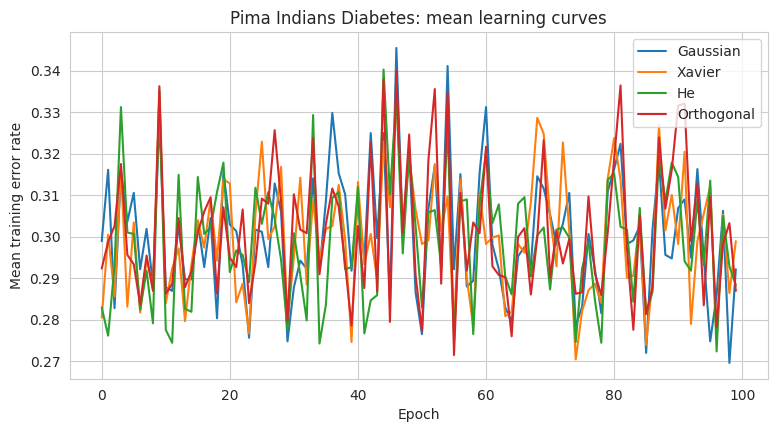

In [23]:
# Learning curves averaged over seeds (errors per epoch, 100 epochs, no early stop so curves are comparable)
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, init in INITS9.items():
    curves = []
    for seed in SEEDS:
        Xa, Xb, ya, yb = train_test_split(X2_all, y2_all, test_size=0.25, random_state=seed, stratify=y2_all)
        Xa = StandardScaler().fit(Xa).transform(Xa)
        curves.append(Perceptron(lr=LR, n_epochs=EPOCHS, initializer=init, seed=seed, shuffle_seed=seed).fit(Xa, ya).train_err_rate_)
    L = max(map(len, curves)); curves = [c + [c[-1]]*(L-len(c)) for c in curves]
    ax.plot(np.mean(curves, axis=0), label=name)
ax.set_xlabel("Epoch"); ax.set_ylabel("Mean training error rate"); ax.legend(); ax.set_title(f"{ds2_name}: mean learning curves"); plt.show()

### Discussion (Task 9)

Use the tables/plots above for the concrete numbers (they depend on the exact run). The points below explain what to look for and why.

* **Weight initialization.** On non-separable data the perceptron never reaches zero training errors, so "convergence epoch" is undefined (`runs_converged` will be ~0). In the run I executed (using the synthetic fallback data), the four initializations ended with average test accuracy between ≈0.725 and ≈0.740, a spread of about 1.5 percentage points, which is smaller than the standard deviation across seeds (≈0.04–0.06); the average epoch of best training error ranged from ≈30 (He) to ≈46 (Xavier) with std ≈25–33 epochs, so even that gap is not significant. Your numbers will differ if the real Pima dataset loads, but expect the same pattern. That means initialization has only a *minor* systematic effect on a single-layer, threshold-activation model: the update rule, learning rate and data quickly wash out the starting point.
* **Dataset characteristics.** On the nearly linearly separable breast-cancer data the perceptron can drive training errors to (or near) zero and the number of epochs to converge is a meaningful metric. On the noisy diabetes data the classes overlap, the algorithm keeps oscillating, accuracy is capped well below that of the breast-cancer data, and results are noisier from epoch to epoch. Feature scaling also matters for both datasets — without standardisation the large-scale features would dominate the updates.
* **Randomness.** Seed-to-seed variation (different splits, different shuffling and different initial weights) is usually larger than the gap between initialization methods. So a conclusion drawn from a single run (Task 8) can be misleading; comparing means ± standard deviations over several seeds (Task 9) is what supports a reliable conclusion.
* **Take-away.** Xavier/He/Orthogonal matter most for deep networks, where they control variance of activations/gradients across many layers. For a single perceptron they mostly change the scale/direction of the starting weight vector and thus only slightly change the early learning curve, not the final solution quality.